In [1]:
# %pip install xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
sns.set()

In [3]:
# Load Data

df = pd.read_csv("Loan_default.csv")
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [4]:
df.isnull().sum()

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [5]:
df.dtypes

LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

In [6]:
df.shape

(255347, 18)

In [7]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='str')

In [8]:
df.drop("LoanID",axis=1,inplace=True)
df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [9]:
unique = df["MaritalStatus"].unique()
unique

<ArrowStringArray>
['Divorced', 'Married', 'Single']
Length: 3, dtype: str

In [10]:
# 'Education', 'EmploymentType', 'MaritalStatus','HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner'

binary_col = ["HasMortgage","HasDependents","HasCoSigner"]

for col in binary_col:
    df[col] = df[col].map({"Yes": 1 , "No" : 0}) 

In [11]:
categorical_col = ["Education","EmploymentType","MaritalStatus","LoanPurpose"]

for col in categorical_col:
    df[col]= df[col].astype("category").cat.codes

df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,0,0,0,1,1,4,1,0
1,69,50432,124440,458,15,1,4.81,60,0.68,2,0,1,0,0,4,1,0
2,46,84208,129188,451,26,3,21.17,24,0.31,2,3,0,1,1,0,0,1
3,32,31713,44799,743,0,3,7.07,24,0.23,1,0,1,0,0,1,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,0,3,0,0,1,0,0,0


In [12]:
# Target And Feature 

x = df.drop("Default",axis=1)
y = df["Default"]

In [13]:
# Train Test Split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [14]:
# Random Forst For Begging

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(x_train,y_train)
rf_pred = rf.predict(x_test)

print("Accuracy Score :", accuracy_score(y_test,rf_pred))
print("Classification Report  :", classification_report(y_test,rf_pred))


Accuracy Score : 0.8869786567456432
Classification Report  :               precision    recall  f1-score   support

           0       0.89      1.00      0.94     45170
           1       0.65      0.05      0.09      5900

    accuracy                           0.89     51070
   macro avg       0.77      0.52      0.51     51070
weighted avg       0.86      0.89      0.84     51070



In [18]:
# XGBoost Model

xgb = XGBClassifier(
    n_estimators = 300,
    learning_rate = (0.05),
    max_depth = 4,
    random_state = 42
)

xgb.fit(x_train,y_train)
xgb_pred = xgb.predict(x_test)

print("Accuracy :- ",accuracy_score(y_test,xgb_pred))
print("Classification Report =", classification_report(y_test,xgb_pred))
print("confusion_matrix = \n",confusion_matrix(y_test,xgb_pred))

Accuracy :-  0.8877423144703348
Classification Report =               precision    recall  f1-score   support

           0       0.89      0.99      0.94     45170
           1       0.63      0.07      0.12      5900

    accuracy                           0.89     51070
   macro avg       0.76      0.53      0.53     51070
weighted avg       0.86      0.89      0.85     51070

confusion_matrix = 
 [[44940   230]
 [ 5503   397]]


Text(0.5, 1.0, 'Random Forest Confusion Matrix')

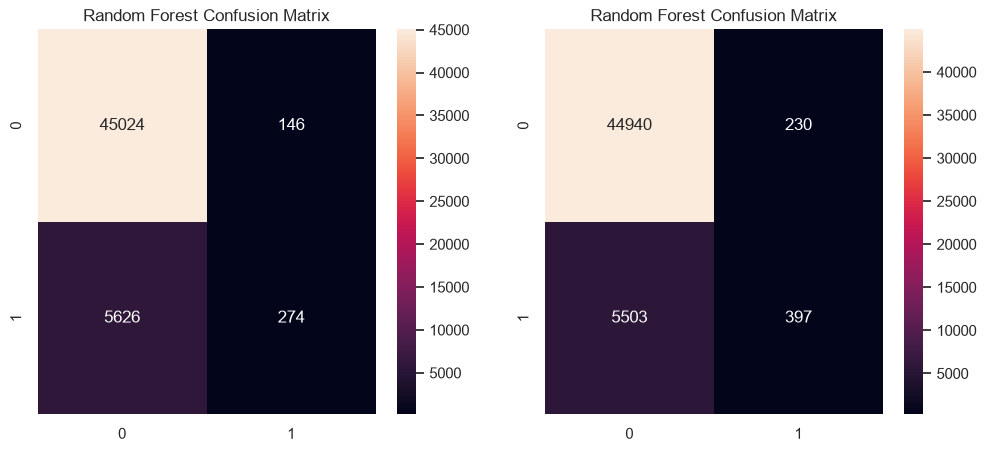

In [ ]:
# Confusion Matrix

fig, ax = plt.subplots(1,2,figsize=(12,5))
sns.heatmap(confusion_matrix(y_test,rf_pred),annot=True,fmt="d",ax=ax[0])
ax[0].set_title("Random Forest Confusion Matrix")

sns.heatmap(confusion_matrix(y_test,xgb_pred),annot=True,fmt="d",ax=ax[1])
ax[1].set_title("Random Forest Confusion Matrix")

plt.show()

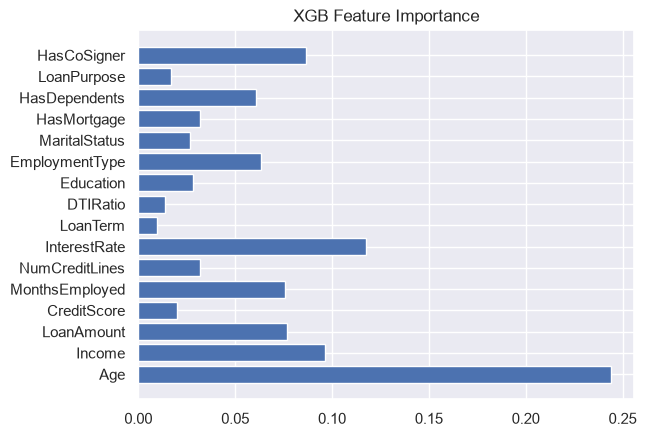

In [22]:
importance = xgb.feature_importances_
plt.barh(x.columns,importance)
plt.title("XGB Feature Importance")

plt.show()